# STJEPA V2 Benchmarking

- Creators: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 30.06.2025
- Date of Last Modification: 14.04.2026 (by Sebastian Birk (sb75@sanger.ac.uk)

- Run this notebook in the stjepa_v2 uv environment, installable from ```../../envs/stjepa_v2.sh``` (on v2 branch).

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import gc
import logging
import os
import warnings

import anndata as ad
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import scipy.sparse as sp
import sklearn.metrics as skm
import torch
import squidpy as sq
from datasets import concatenate_datasets, load_from_disk
from itertools import combinations
from matplotlib.colors import Normalize
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler

from app.inference import (embed_dataset,
                           harmonize_adata,
                           perturb_dataset,
                           tokenize_adata,
                           harmonize_tokenize_embed_pipeline,
                           get_gene_embed,
                           get_average_gene_embed,
                           get_spatial_score,
                           get_emd_distance)
from app.utils import init_model, load_checkpoint
from stjepa.utils.evaluation import (get_top_gene_score,
                                     get_top_gene_pairs)

from analysis_utils import *

/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


### 1.2 Define Config

In [4]:
method = 'stjepa_v2'

# General params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
n_pcs = None

# STJEPA params
#model_timestamp = '21032026_085513_196'
model_timestamp = '11042026_143823_714'
emb_key = 'neighborhood_emb'
sample_key = None
min_cells_per_gene = 0
min_genes_per_cell = 10
nproc = 4
processing_mode = 'parallel'
use_generator = True
num_shards = 32
ensembl_release = 110
gene_mapping_dict_file_path = None
gene_occurrence_count_file_path = None
gene_occurrence_count_filter_value = 10
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_genes = None
top_k = None
batch_key_new = 'batch_new'

# Clustering params
#latent_leiden_resolution = 1.32
latent_leiden_resolution = 0.4 # latent_leiden_resolution = 0.27

### 1.3 Configure Paths

In [5]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/stjepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

cache_directory_path = f'{benchmarking_artifacts_folder_path}/{method}/cache'
model_folder_path = f'{artifacts_folder_path}/models/{model_timestamp}'

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

pd.options.future.infer_string = False

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [10]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}/cache', exist_ok=True)

### 1.5 Define Functions

In [11]:
def make_large_cmap(n):
    base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"
    return [mcolors.to_hex(base(i)) for i in range(n)]

In [12]:
def mmd_comparable(adata, emb_key, batch_key, n_sub=2000, n_sigma=1000):
    # Normalize to zero mean, unit variance
    X = StandardScaler().fit_transform(adata.obsm[emb_key])
    
    # Compute sigma on normalized data
    idx = np.random.choice(len(X), min(n_sigma, len(X)), replace=False)
    sub = X[idx]
    dists = np.linalg.norm(sub[:, None] - sub[None, :], axis=2)
    sigma = np.median(dists[dists > 0])
    
    # Split by batch
    batches = adata.obs[batch_key].unique()
    mask0 = adata.obs[batch_key] == batches[0]
    mask1 = adata.obs[batch_key] == batches[1]
    b0, b1 = X[mask0], X[mask1]
    
    idx0 = np.random.choice(len(b0), min(n_sub, len(b0)), replace=False)
    idx1 = np.random.choice(len(b1), min(n_sub, len(b1)), replace=False)
    
    def rbf(A, B):
        d = np.linalg.norm(A[:, None] - B[None, :], axis=2)
        return np.exp(-d**2 / (2 * sigma**2))
    
    b0s, b1s = b0[idx0], b1[idx1]
    return rbf(b0s, b0s).mean() + rbf(b1s, b1s).mean() - 2 * rbf(b0s, b1s).mean()

## 2. Analysis

### 2.1 Retrieve Embeddings

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

In [ ]:
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key_new,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    gene_mapping_dict_file_path=gene_mapping_dict_file_path,
    gene_occurrence_count_file_path=gene_occurrence_count_file_path,
    gene_occurrence_count_filter_value=gene_occurrence_count_filter_value,
    ensembl_release=ensembl_release,
    species=species,
    gene_perturb_df=None,               
    nproc=nproc,
    processing_mode=processing_mode,
    harmonized_adata_save_path=f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}.h5ad",
    save_dataset_path=f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}.dataset",
    num_shards=num_shards,
    emb_layer=emb_layer,
    agg_excluded_genes=agg_excluded_genes,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    use_generator=use_generator,
    add_neigh_cell_ids=False,
    min_cells_per_gene=min_cells_per_gene,
    min_genes_per_cell=min_genes_per_cell)

In [ ]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}_embedded.h5ad')

### 2.2 Visualize UMAP

In [ ]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                n_pcs=n_pcs, key_added=emb_key)
sc.tl.umap(adata, neighbors_key=emb_key)

n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
adata.obs[batch_key] = adata.obs[batch_key].astype('category')
categories = adata.obs[batch_key].cat.categories.tolist()
assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

sc.pl.umap(
    adata,
    color=batch_key,
    title="Technology",
    legend_loc="right margin",
    legend_fontsize=10,
    show=False,
)
for collection in plt.gca().collections:
    collection.set_rasterized(True)
plt.savefig(
    f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
    format="svg", bbox_inches="tight"
)
plt.show()
plt.close()

for label_key in label_keys:
    n_cats = adata.obs[label_key].nunique()
    palette = make_large_cmap(n_cats)
    sc.pl.umap(adata, color=label_key, palette=palette, show=False)
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [ ]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}_embedded.h5ad')

### 2.3 Visualize Niches

In [ ]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}_embedded.h5ad')

In [55]:
# Plot embedding-based clusters
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"

sc.tl.leiden(adata,
             neighbors_key=emb_key,
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution,
             flavor="igraph",
             n_iterations=2)

In [56]:
print(adata.obs[latent_cluster_key].nunique())
print(adata.obs[latent_cluster_key].value_counts())

34
neighborhood_emb_clusters_res_0.4
9     8616
8     6171
1     5752
10    5194
6     5002
0     4701
26    4418
11    4191
5     3871
3     3702
20    3332
28    3102
21    2906
18    2390
4     2301
25    1943
7     1840
22    1831
33    1711
16    1461
12    1321
15    1303
24    1244
23    1153
14     882
13     868
19     767
31     622
2      604
30     591
29     549
27     496
32     476
17     393
Name: count, dtype: int64


In [57]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}_embedded_clustered.h5ad')

In [58]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}_embedded_clustered.h5ad')
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"

In [59]:
custom_palette['17'] = '#E07C24'  # warm amber
custom_palette['20'] = '#4682B4'  # steel blue
custom_palette['24'] = '#C4A35A'  # muted gold

/tmp/ipykernel_176686/3547469904.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


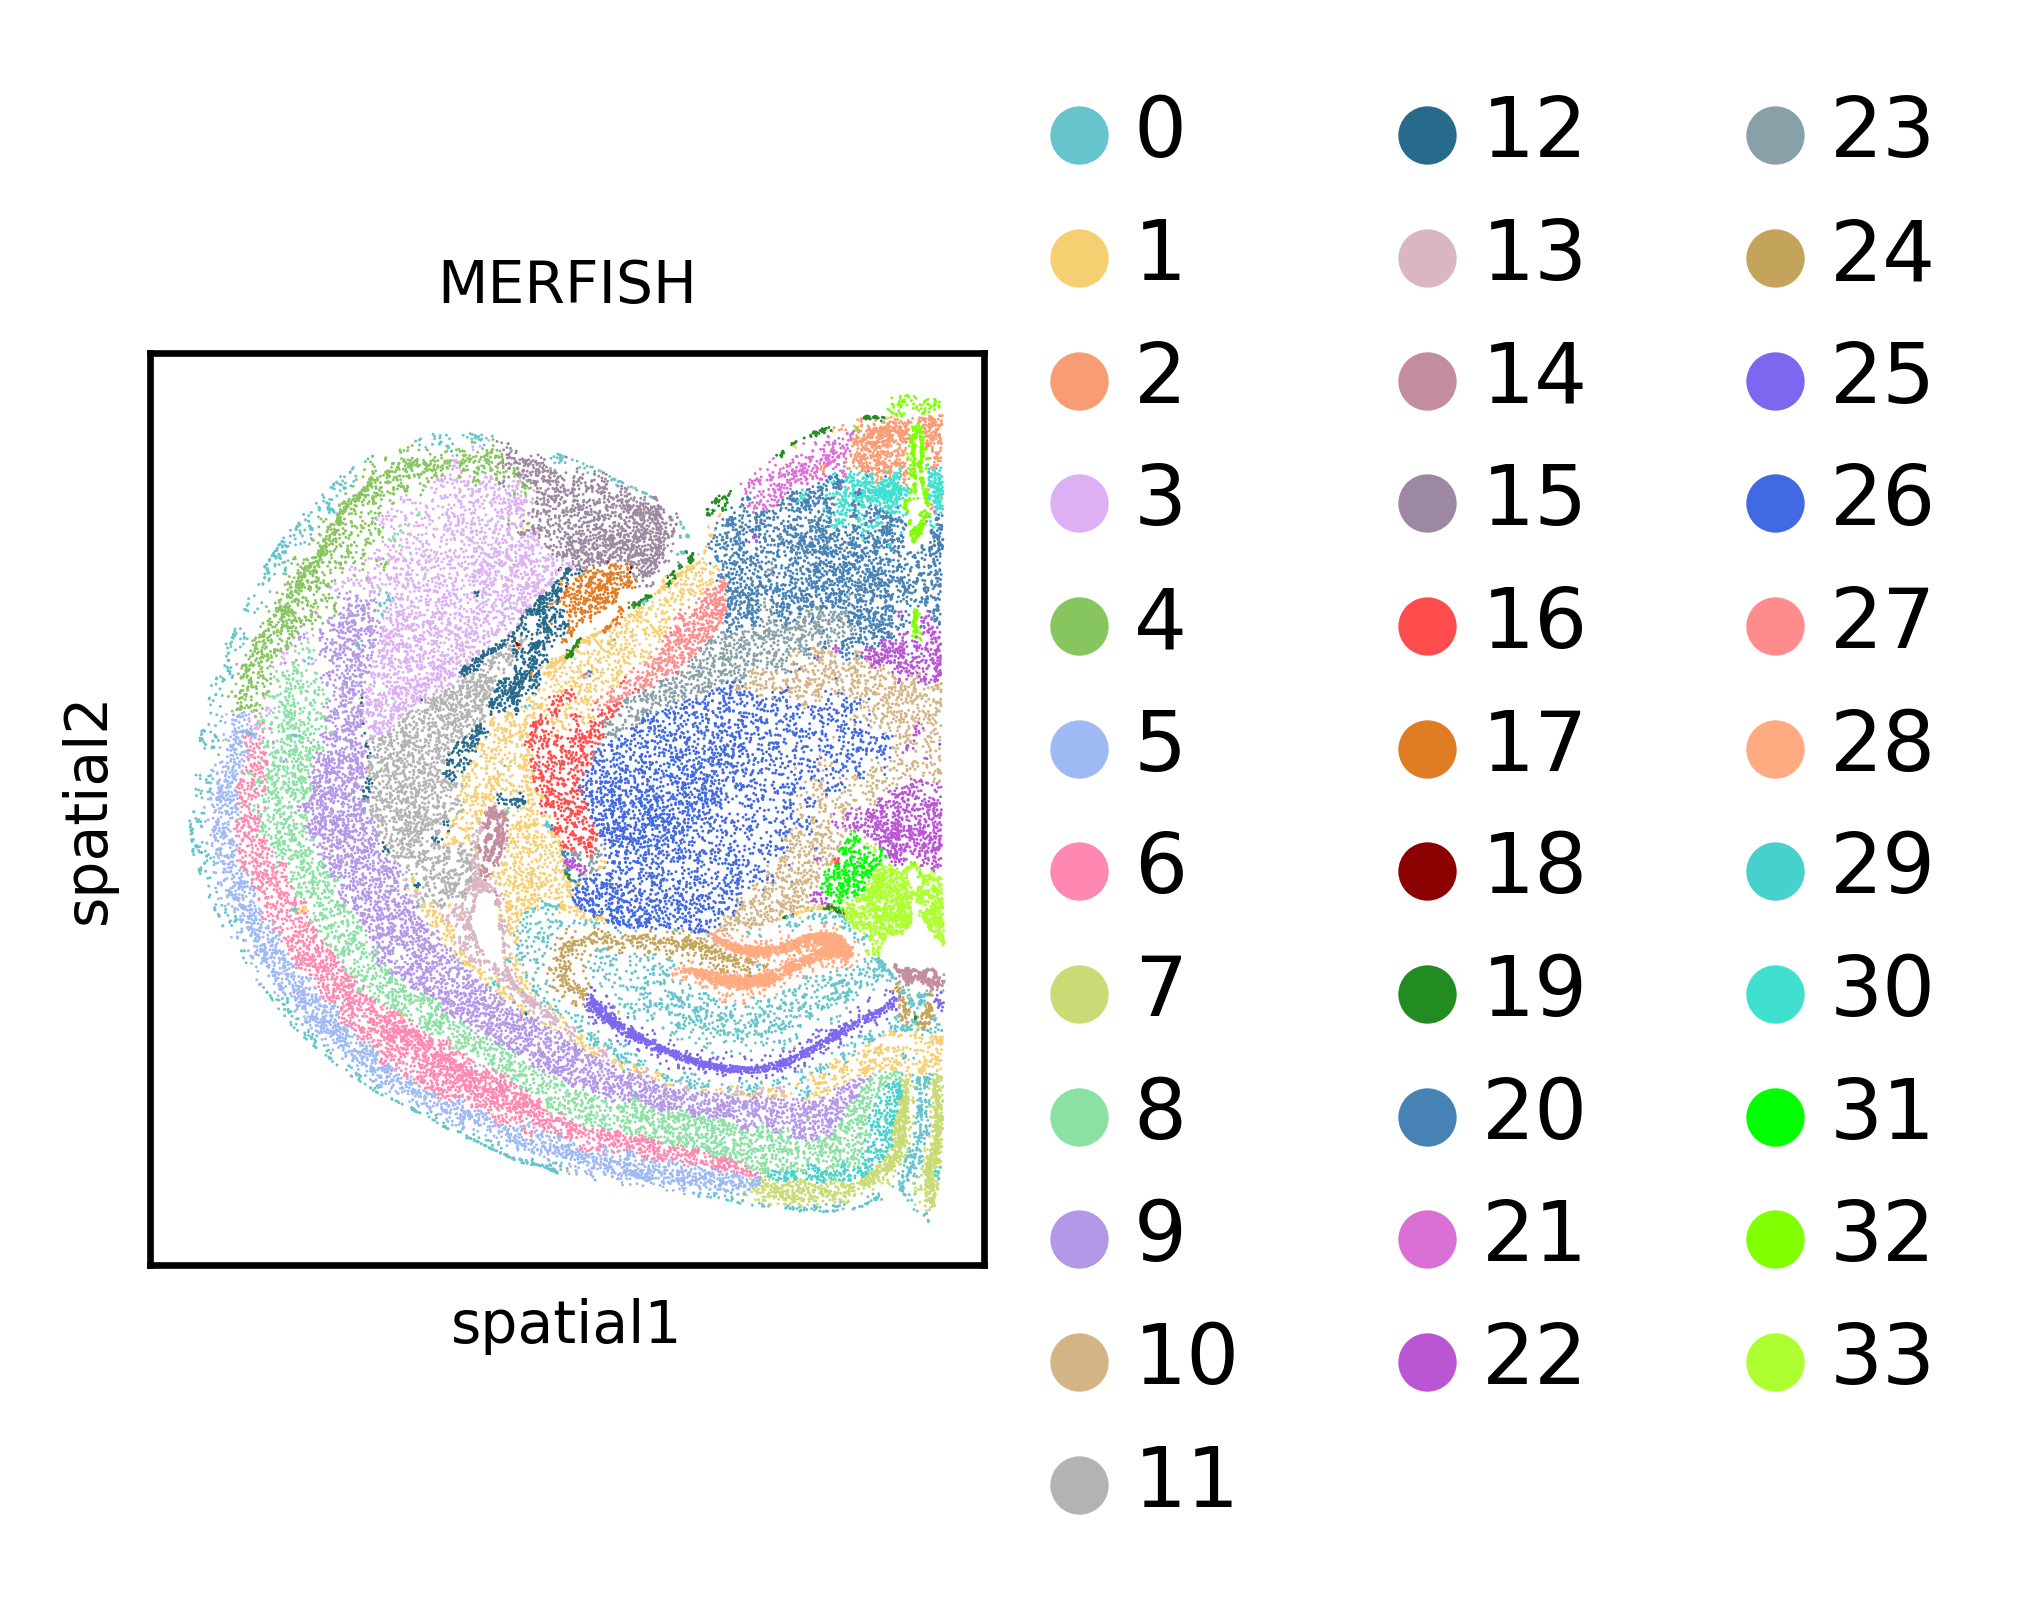

/tmp/ipykernel_176686/3547469904.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


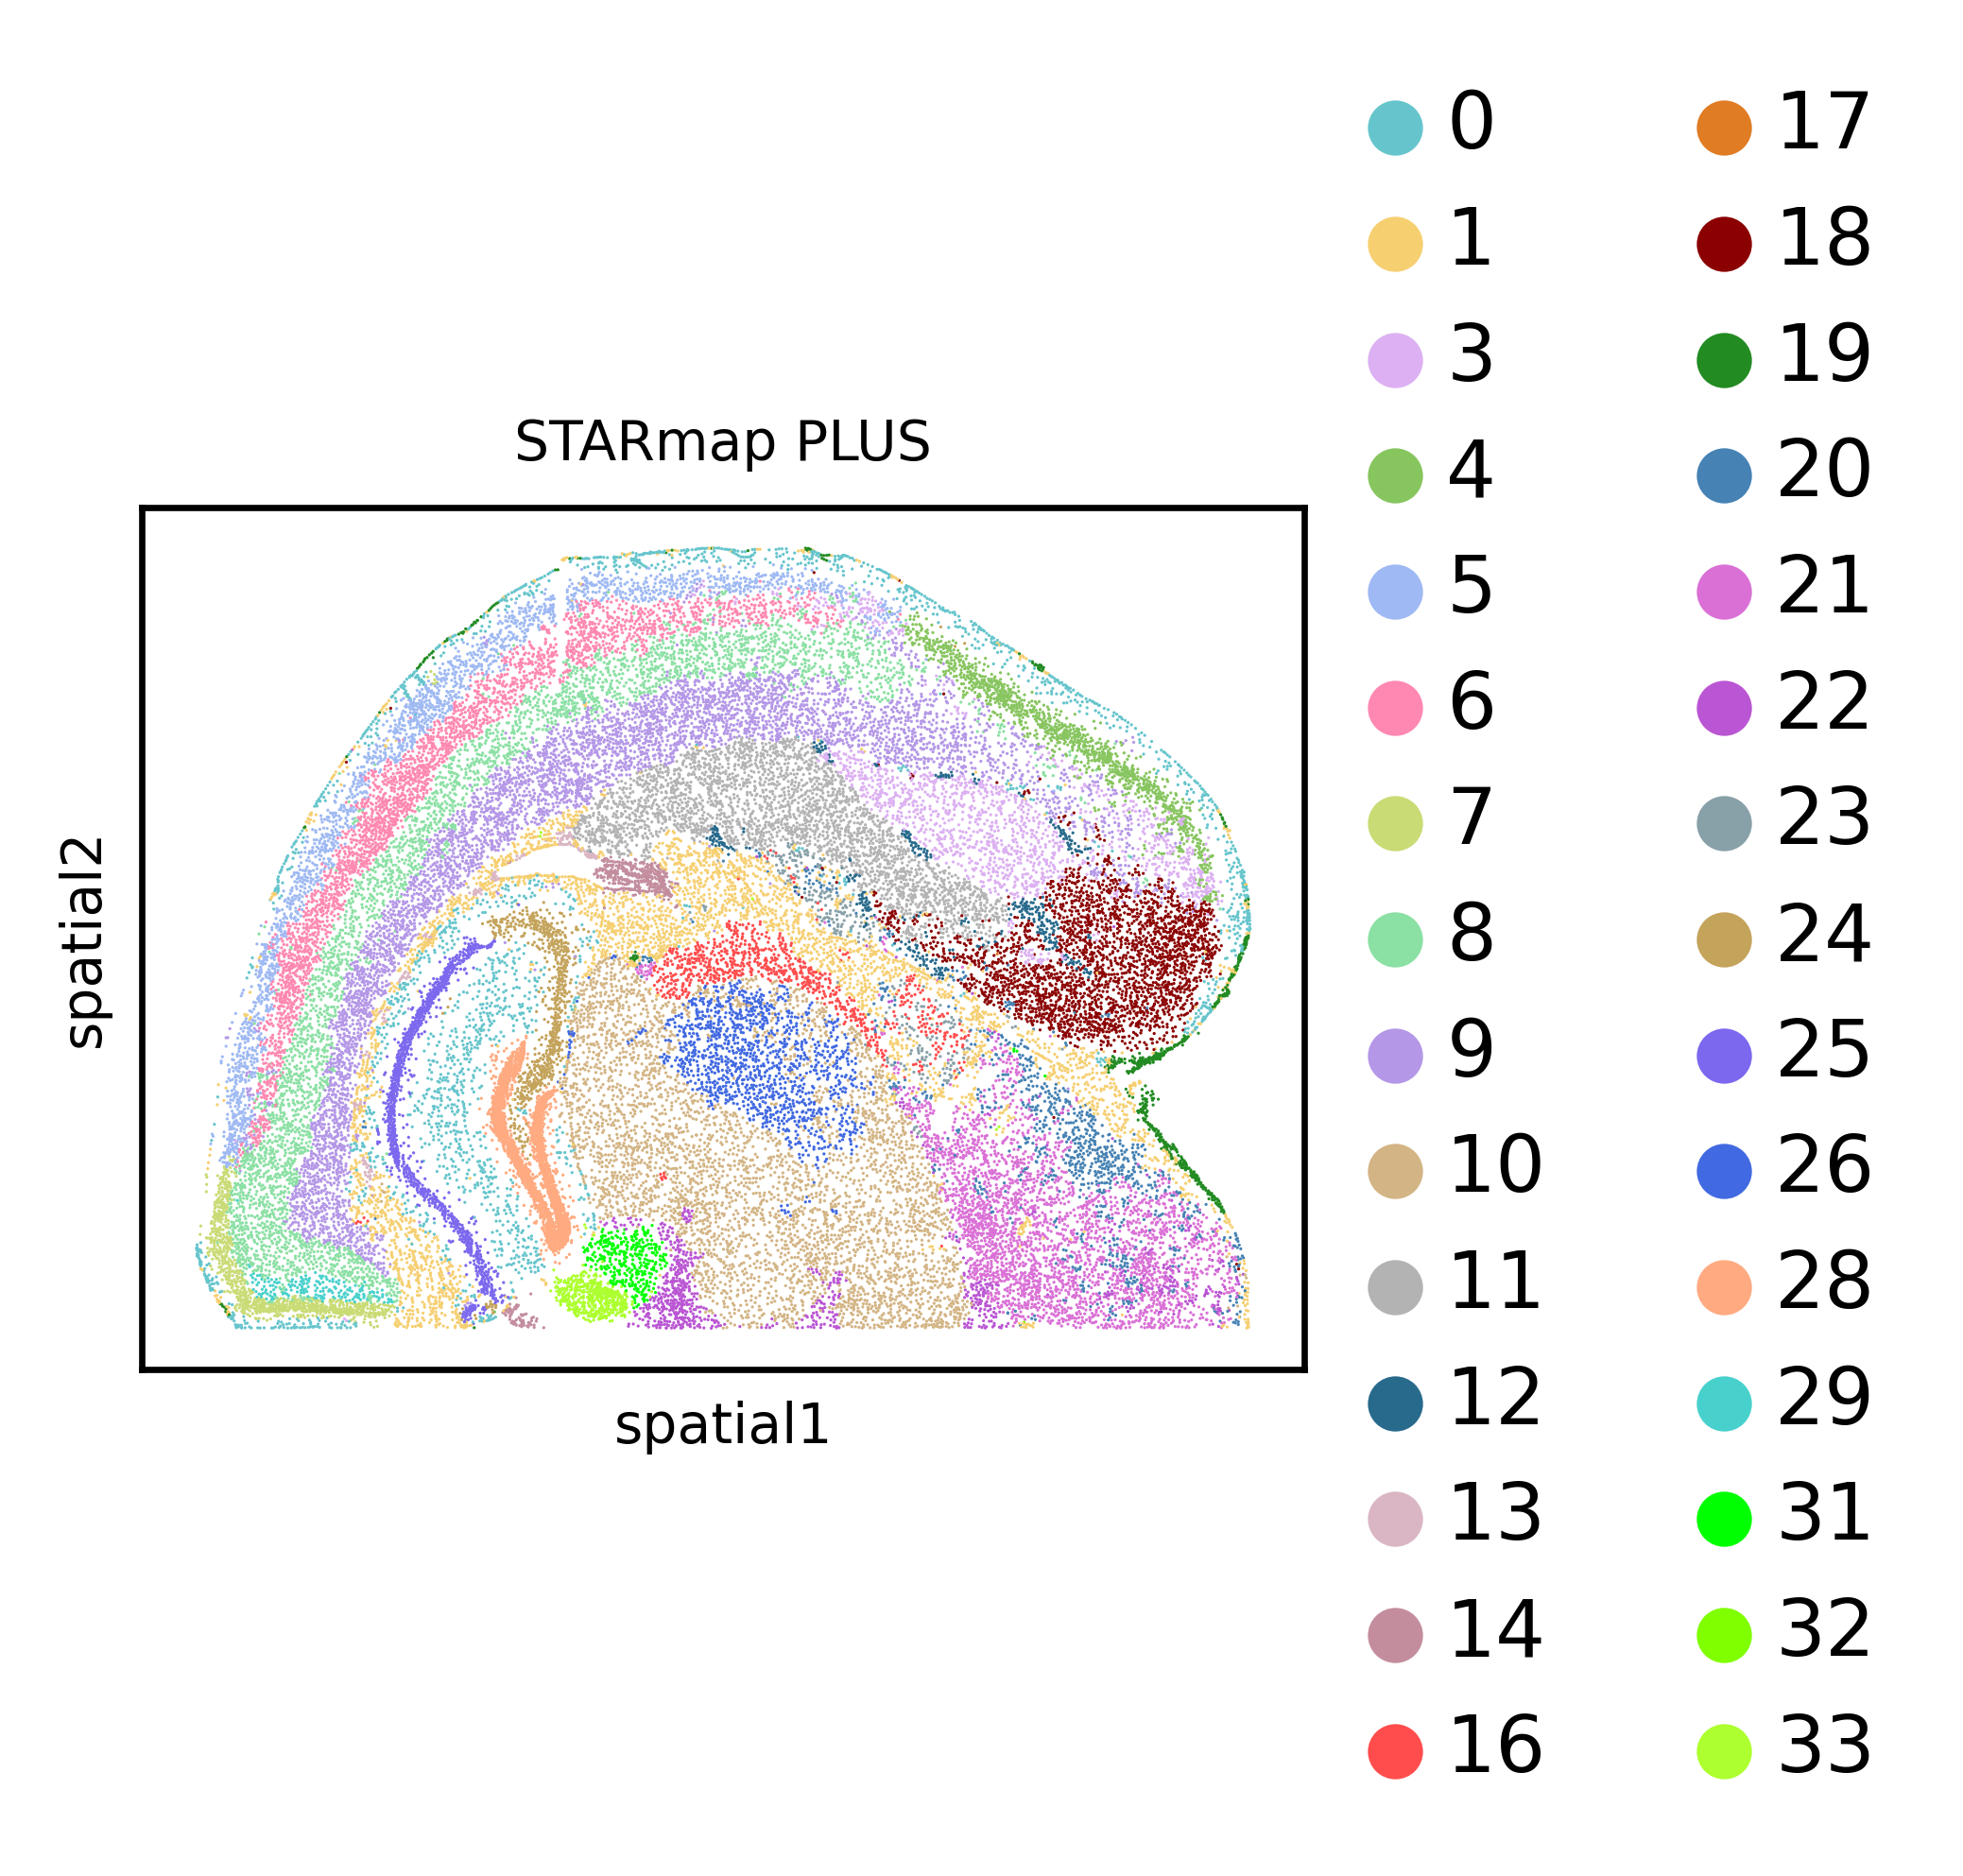

In [60]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

### 2.4 Compute Metrics

In [61]:
# Compute average cosine similarity of embeddings
X = adata.obsm[emb_key]
X = X / np.linalg.norm(X, axis=1, keepdims=True)
n = X.shape[0]
S = X.sum(axis=0)
avg_cos_sim = (S @ S - n) / (n * (n - 1))
print(f'{emb_key} average cosine similarity: {avg_cos_sim}')

cos_sim_result = pd.DataFrame([{
    "emb_key": emb_key,
    "avg_cosine_similarity": avg_cos_sim,
}])

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/"
    f"{dataset_name}_{emb_key}_avg_cosine_similarity.csv"
)
cos_sim_result.to_csv(out_path, index=False)
print(f"Saved → {out_path}")

neighborhood_emb average cosine similarity: 0.2502085566520691
Saved → /nfs/team361/sb75/stjepa-reproducibility/artifacts/benchmarking/stjepa_v2/11042026_143823_714/mmb0-1b_smb1-1b_1p_neighborhood_emb_avg_cosine_similarity.csv


In [62]:
# Compute NMI and ARI with region annotations
results = []
for region_key in ["Sub_molecular_tissue_region", "ccf_region_name"]:
    mask = adata.obs[region_key].notna()
    labels_true = adata.obs.loc[mask, region_key]
    labels_pred = adata.obs.loc[mask, latent_cluster_key]
    nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
    ari = skm.adjusted_rand_score(labels_true, labels_pred)
    print(f"NMI ({region_key}): {nmi:.4f}")
    print(f"ARI ({region_key}): {ari:.4f}")
    results.append({"region_key": region_key, "NMI": nmi, "ARI": ari})

df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}_{latent_cluster_key}_niche_identification_metrics.csv",
    index=False
)

NMI (Sub_molecular_tissue_region): 0.7067
ARI (Sub_molecular_tissue_region): 0.4238
NMI (ccf_region_name): 0.6452
ARI (ccf_region_name): 0.2674


In [63]:
# Compute batch integration metrics
results = []

# iLISI
batch = adata.obs[batch_key].values
knn = pynndescent(adata.obsm[emb_key], n_neighbors=90)
ilisi = float(np.mean(ilisi_knn(knn, batch)))
print(f"iLISI: {ilisi:.4f}")
results.append({"metric": "iLISI", "score": ilisi})

# ASW
asw = silhouette_score(
    adata.obsm[emb_key],
    adata.obs["batch"],
    metric="euclidean",
    sample_size=10000
)
print(f"ASW batch: {asw:.4f}")
results.append({"metric": "ASW", "score": asw})

# MMD
mmd_score = mmd_comparable(adata, emb_key, batch_key)
print(f"MMD: {mmd_score:.4f}")
results.append({"metric": "MMD", "score": mmd_score})

# Save
df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}_{emb_key}_batch_integration_metrics.csv",
    index=False
)

INFO:2026-04-14 10:09:09,450:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


iLISI: 0.1457
ASW batch: 0.0110
MMD: 0.0118


In [ ]:
# --- Config -----------------------------------------------------------
latent_leiden_resolution = 1.0
N_STEPS   = 4      # points above and below base resolution
STEP_SIZE = 0.1
MIN_RES   = 0.1    # Leiden resolution must be > 0

region_keys = ["Sub_molecular_tissue_region", "ccf_region_name"]

# Build resolution grid: N_STEPS below and above base, clamped to MIN_RES
# Use integer steps to avoid float accumulation errors in np.arange
base_int = round(latent_leiden_resolution / STEP_SIZE)  # e.g. 1.0/0.1 -> 10
resolutions = [
    round(step * STEP_SIZE, 1)
    for step in range(base_int - N_STEPS, base_int + N_STEPS + 1)
    if step * STEP_SIZE >= MIN_RES
]

# --- Sweep ------------------------------------------------------------
all_results = []

for res in resolutions:
    cluster_key = f"{emb_key}_clusters_res_{res}"

    # Leiden clustering
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=cluster_key,
                      resolution=res,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=cluster_key,
                     resolution=res,
                     flavor="igraph",
                     n_iterations=2)

    n_clusters = adata.obs[cluster_key].nunique()
    print(f"\n── Resolution {res:.1f}  ({n_clusters} clusters) ──")

    for region_key in region_keys:
        mask        = adata.obs[region_key].notna()
        labels_true = adata.obs.loc[mask, region_key]
        labels_pred = adata.obs.loc[mask, cluster_key]

        nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
        ari = skm.adjusted_rand_score(labels_true, labels_pred)
        print(f"  {region_key:40s}  NMI={nmi:.4f}  ARI={ari:.4f}")

        all_results.append({
            "resolution": res,
            "n_clusters": n_clusters,
            "region_key": region_key,
            "NMI":        nmi,
            "ARI":        ari,
        })

# --- Save -------------------------------------------------------------
df = pd.DataFrame(all_results)

# Canonical column order
df = df[["resolution", "n_clusters", "region_key", "NMI", "ARI"]]

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/"
    f"{dataset_name}_{emb_key}_niche_identification_metrics_res_sweep.csv"
)
df.to_csv(out_path, index=False)
print(f"\nSaved {len(df)} rows → {out_path}")